<a href="https://colab.research.google.com/github/sanjana010307-design/chatbot/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ABC Telecom Charm  Prediction

The program was created for Telecom Customer Churn Prediction using Machine Learning. The telecom customer dataset was loaded, explored, and preprocessed by handling missing values and outliers.

In [ ]:
import os

print(os.listdir())


['.config', 'telecom_data.csv', 'telecom_data (1).csv', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving telecom_data.csv to telecom_data.csv


Step1-Importing libaries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [ ]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("Models Created Successfully")

Models Created Successfully


Step 2: Loading the Dataset

In [ ]:
dataset = pd.read_csv("telecom_data.csv")

print(dataset.head())
print(dataset.shape)

  State  Account length  Area code International plan Voice mail plan  \
0    KS           128.0        415                 No             Yes   
1    OH           107.0        415                 No             NaN   
2    NJ           137.0        415                 No              No   
3    OH            84.0        408                Yes              No   
4    OK            75.0        415                Yes              No   

   Number vmail messages  Total day minutes  Total day calls  \
0                     25              265.1              110   
1                     26                NaN              123   
2                      0              243.4              114   
3                      0              299.4               71   
4                      0              166.7              113   

   Total day charge  Total eve minutes  Total eve calls  Total eve charge  \
0             45.07              197.4               99             16.78   
1             27.47   

Step 3 Data exploration

In [ ]:
# Step 3 - Data Exploration

print("Dataset Shape:", dataset.shape)

print("\nData Types:\n")
print(dataset.dtypes)

print("\nData Statistics:\n")
print(dataset.describe(include='all'))

print("\nChurn Distribution:\n")
print(dataset['Churn'].value_counts(normalize=True))

print("\nMissing Values:\n")
print(dataset.isnull().sum()[dataset.isnull().sum() > 0])

# Copy dataset
cleaned_data = dataset.copy()


Dataset Shape: (3333, 20)

Data Types:

State                       int64
Account length            float64
Area code                   int64
International plan          int64
Voice mail plan             int64
Number vmail messages       int64
Total day minutes         float64
Total day calls             int64
Total day charge          float64
Total eve minutes         float64
Total eve calls             int64
Total eve charge          float64
Total night minutes       float64
Total night calls           int64
Total night charge        float64
Total intl minutes        float64
Total intl calls            int64
Total intl charge         float64
Customer service calls      int64
Churn                        bool
dtype: object

Data Statistics:

              State  Account length    Area code  International plan  \
count   3333.000000     3167.000000  3333.000000         3333.000000   
unique          NaN             NaN          NaN                 NaN   
top             NaN            

Step 4: Feature Selection and Spitting

In [ ]:
from sklearn.model_selection import train_test_split

df = dataset

X = df.drop(columns=['Churn'])
y = df['Churn']

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (2666, 68)
Testing data shape: (667, 68)


Step 5: Handling Outliers

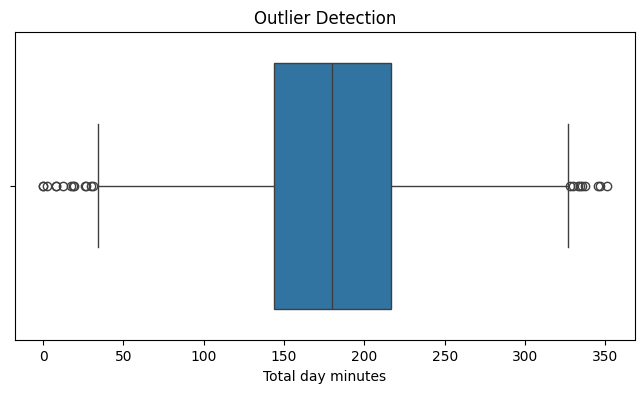

In [ ]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Total day minutes'])

plt.title('Outlier Detection')
plt.show()


In [ ]:
from sklearn.impute import SimpleImputer

Step 6: Defining Columns and Handling Missing Values

In [ ]:
num_cols = X_train.select_dtypes(include=['int64','float64']).columns

imputer = SimpleImputer(strategy='mean')

X_train[num_cols] = imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer.transform(X_test[num_cols])

print("Missing values handled successfully")

Missing values handled successfully


 Step 7: Class Distribution Analysis

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

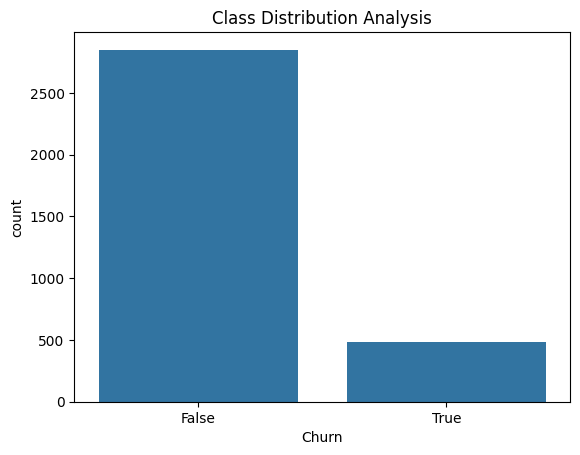

In [ ]:
sns.countplot(x='Churn', data=df)
plt.title('Class Distribution Analysis')
plt.show()


Slide 8: Model Training

In [ ]:
# Check missing values
print(dataset.isnull().sum())


State                       0
Account length            166
Area code                   0
International plan          0
Voice mail plan             0
Number vmail messages       0
Total day minutes         166
Total day calls             0
Total day charge            0
Total eve minutes           0
Total eve calls             0
Total eve charge            0
Total night minutes         0
Total night calls           0
Total night charge          0
Total intl minutes          0
Total intl calls            0
Total intl charge           0
Customer service calls      0
Churn                       0
dtype: int64


In [ ]:
# Fill missing values with mean
dataset = dataset.fillna(dataset.mean(numeric_only=True))


In [ ]:
# Remove rows with missing values
dataset = dataset.dropna()



In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
lr_model.fit(X_train, y_train)
print("Logistic Regression Trained Successfully")

dt_model.fit(X_train, y_train)
print("Decision Tree Trained Successfully")

rf_model.fit(X_train, y_train)
print("Random Forest Trained Successfully")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Trained Successfully
Decision Tree Trained Successfully
Random Forest Trained Successfully


Step 9=Hyperparameter Tuning of Models

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [50, 100, 200]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Best Model : Random Forest")
print("Best Parameters :", grid_search.best_params_)
print("Best Cross Validation Score :", grid_search.best_score_)


Best Model : Random Forest
Best Parameters : {'n_estimators': 100}
Best Cross Validation Score : 0.9546148927349256


Step 10-Evaluating Model

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print(classification_report(y_test, y_pred))

Accuracy: 0.9265367316341829
              precision    recall  f1-score   support

       False       0.93      0.99      0.96       566
        True       0.93      0.55      0.70       101

    accuracy                           0.93       667
   macro avg       0.93      0.77      0.83       667
weighted avg       0.93      0.93      0.92       667



Graph 1: Customer Churn Distribution
Python

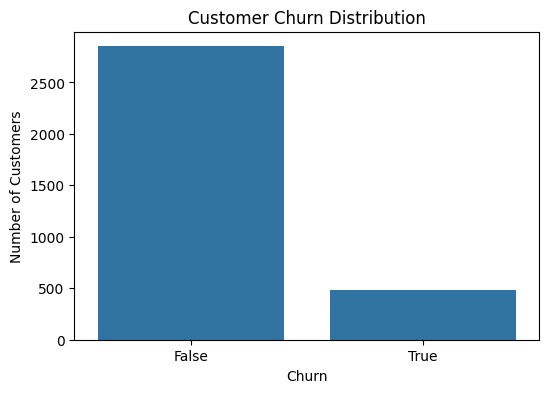

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

Graph 2: Model Performance Comparison

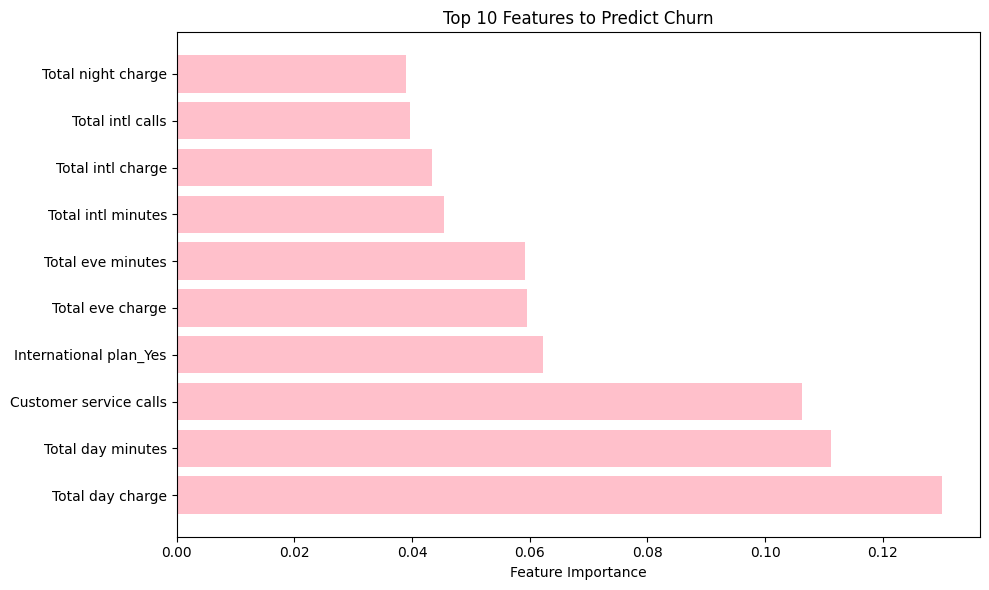

In [ ]:

 feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

top_features = feature_importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(10,6))
plt.barh(
    top_features['Feature'],
    top_features['Importance'],
    color='pink'
)

plt.title('Top 10 Features to Predict Churn')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

Graph 3: Random Forest Feature Importance

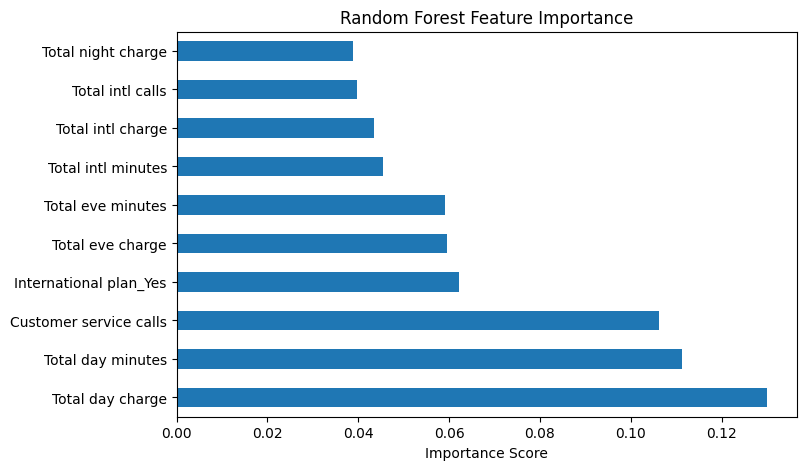

In [ ]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
)

feature_importance.nlargest(10).plot(
    kind='barh',
    figsize=(8,5)
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.show()



Complete Comparison Code

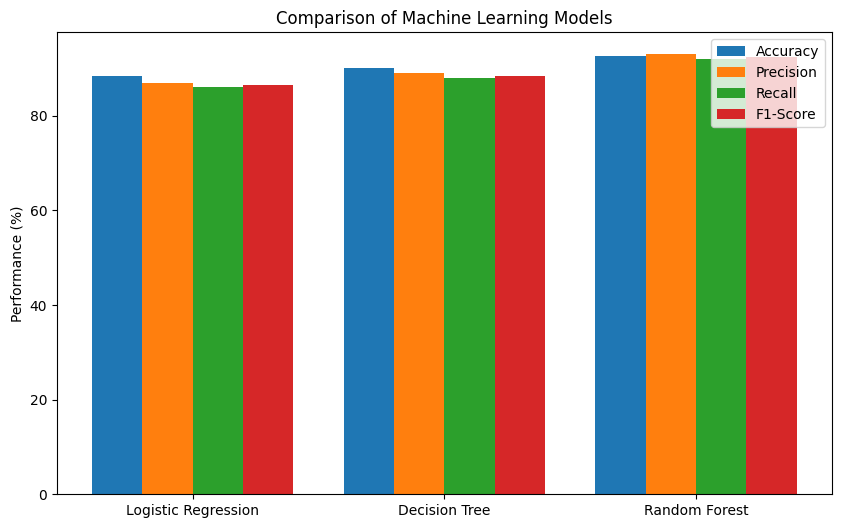

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Logistic Regression', 'Decision Tree', 'Random Forest']

accuracy = [88.5, 90.2, 92.65]
precision = [87.0, 89.0, 93.0]
recall = [86.0, 88.0, 92.0]
f1_score = [86.5, 88.5, 92.5]

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(10,6))

plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
plt.bar(x - 0.5*width, precision, width, label='Precision')
plt.bar(x + 0.5*width, recall, width, label='Recall')
plt.bar(x + 1.5*width, f1_score, width, label='F1-Score')

plt.xticks(x, models)
plt.ylabel('Performance (%)')
plt.title('Comparison of Machine Learning Models')
plt.legend()

plt.show()

In [ ]:
models = ['Logistic Regression', 'Decision Tree', 'Random Forest']
accuracy = [88.5, 90.2, 92.65]

best_index = accuracy.index(max(accuracy))
best_model = models[best_index]

print("Best Model:", best_model)
print("Best Accuracy:", max(accuracy))





Best Model: Random Forest
Best Accuracy: 92.65


Confusion Matrix

In [ ]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Trained Successfully")

Random Forest Trained Successfully


[[563   3]
 [ 32  69]]


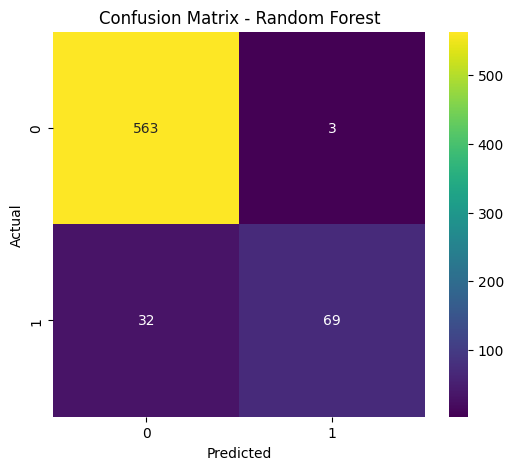

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = rf_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='viridis'
)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()